# PharmaML — The Complete Molecule Generation Workflow (Zero to One Hundred)

One notebook, every stage of a *generative* molecular design project, in the
order you would actually run it — the fifth workflow notebook of the series
(after the ML, docking, PK/PD and cell-line ones). Where those four
**analyse** molecules (model them, dock them, compute their pharmacology),
this one **invents** them: the legacy rar archive shipped training scripts
and docking folders, but no code that ever proposed a new structure —
de novo design lived in nobody's repository. This notebook closes that gap
on a laptop CPU: two complementary optimisers, one shared objective library,
one bundled corpus.

| § | Stage | Toolkit |
|---|---|---|
| 0 | **Setup** — imports, scratch directory | — |
| 1 | **The corpus** — 244 curated drug-like SMILES + property landscape | `pharmaml.generative` |
| 2 | **Objectives** — QED, LogP band, TPSA band, MW band, similarity, pharmacophore, novelty | `pharmaml.generative` |
| 3 | **Multi-objective** — weighted geometric mean, one zero vetoes | `pharmaml.generative` |
| 4 | **De novo generation** — the SMILES genetic algorithm | `pharmaml.generative` |
| 5 | **Seeded generation** — start from your own molecules | `pharmaml.generative` |
| 6 | **Lead optimisation** — scaffold-preserving mutation | `pharmaml.generative` |
| 7 | **Reinforcement learning** — char-GRU prior + REINVENT-style fine-tuning | `pharmaml.generative` |
| 8 | **Novelty** — the anti-rediscovery recipe | `pharmaml.generative` |
| 9 | **GA vs RL** — same objective, head-to-head | `pharmaml.generative` |
| 10 | **Publish** — leaderboard CSV + one-click visual bundle | `pharmaml.viz` |
| 11 | **Recap** | — |

Requires RDKit (`pip install 'pharmaml[chem]'`) for the scoring / GA half and
PyTorch (`pip install 'pharmaml[deep]'`) for the RNN / RL half — both are
imported lazily, so importing the subpackage itself needs neither.


## 0 · Setup

Imports, display options and a scratch directory — every artifact this
notebook writes (the ranked leaderboard, the publish bundle) lands under
`WORK`. Nothing else on your machine is touched.

Every generative run in this notebook pins the same `seed`, so re-running
top-to-bottom reproduces the same leaderboards.


In [1]:
import tempfile
from pathlib import Path

import pandas as pd
import rdkit
import torch

from pharmaml import __version__

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 110)

# Scratch directory for this run's artifacts (use any path you like).
WORK = Path(tempfile.mkdtemp(prefix="generative_workflow_"))

# The shipped demo inventory: the §1b seed table loads from examples/data/
# instead of being embedded inline.
DATA_DIR = Path("data")

# One seed for every run in this notebook: reproducible leaderboards.
SEED = 42

print(f"pharmaml {__version__} · rdkit {rdkit.__version__} · torch {torch.__version__}")
print(f"artifacts -> {WORK}")


pharmaml 1.0.0 · rdkit 2026.09.1 · torch 2.14.1+cpu
artifacts -> /tmp/generative_workflow_v67mknp4


## 1 · The corpus — what the optimisers build from

`DEFAULT_CORPUS` is the bundled, curated starting point: 244 canonical
drug-like SMILES embedded in the package itself (no data file to lose, no
download to fail). "Curated" means exactly what the cell below checks —
every entry parses, every entry is already in RDKit canonical form, and no
entry is duplicated.

CLI equivalent:

```bash
pharmaml generative corpus --out corpus.csv
```


In [2]:
from pharmaml.generative import DEFAULT_CORPUS

n_unique = len(set(DEFAULT_CORPUS))
print(f"corpus size : {len(DEFAULT_CORPUS)} SMILES")
print(f"unique      : {n_unique}")

pd.DataFrame({"smiles": list(DEFAULT_CORPUS[:10])})


corpus size : 244 SMILES
unique      : 244


,smiles
0,CC(=O)Oc1ccccc1C(=O)O
1,CC(=O)Nc1ccc(O)cc1
2,CC(C)Cc1ccc(C(C)C(=O)O)cc1
3,Cn1c(=O)c2c(ncn2C)n(C)c1=O
4,CN(C)C(=N)N=C(N)N
5,CN1CCCC1c1cccnc1
6,CC(=O)CC(c1ccccc1)c1c(O)c2ccccc2oc1=O
7,CN=C(NC#N)NCCSCc1[nH]cnc1C
8,Cn1cnc2c1c(=O)[nH]c(=O)n2C
9,O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl


Before optimising against a corpus, look at it: the property landscape the
search will explore. `compute_descriptors` turns the 244 SMILES into the
full RDKit descriptor table; `plot_descriptor_distributions` renders the
columns that define "drug-like" — molecular weight, LogP, polar surface,
H-bond donors and acceptors.


244 molecules x 217 descriptors


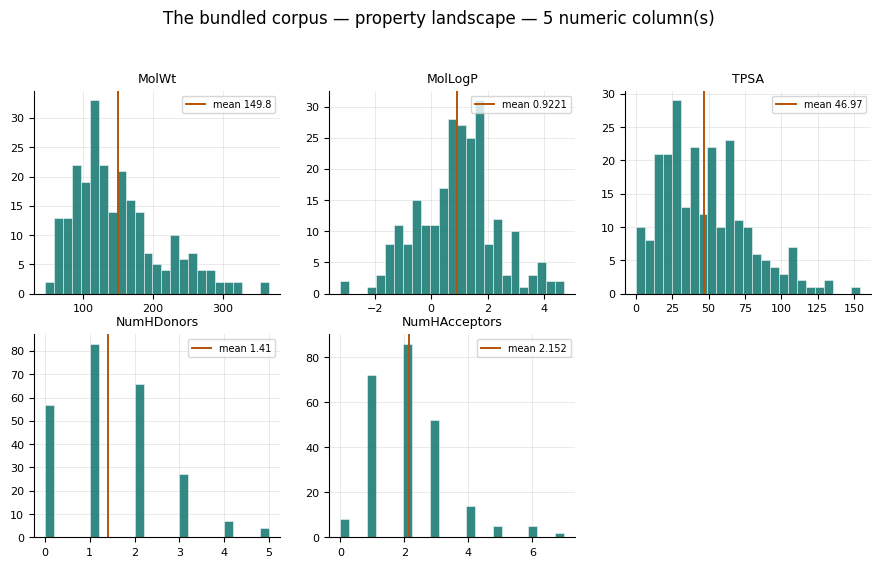

In [3]:
from pharmaml.chem import compute_descriptors
from pharmaml.viz import plot_descriptor_distributions

corpus_desc = compute_descriptors(list(DEFAULT_CORPUS), progress=False)
print(f"{len(corpus_desc)} molecules x {corpus_desc.shape[1] - 1} descriptors")

fig_landscape = plot_descriptor_distributions(
    corpus_desc,
    columns=["MolWt", "MolLogP", "TPSA", "NumHDonors", "NumHAcceptors"],
    title="The bundled corpus — property landscape",
)


## 1b · Your seeds — the "from sample molecules" mode

The optimisers also run **seeded**: hand them a table of your own molecules
and generation 0 starts from those (§5). The demo table below is the
shipped `examples/data/seed_molecules.csv` — 12 named drugs (regenerated
deterministically via `scratch/build_example_data.py`) — point
`SEEDS_CSV` at your own CSV and every cell below runs unchanged.


In [4]:
# --- DEMO SEEDS --------------------------------------------------------
# The 12 named drugs shipped as examples/data/seed_molecules.csv
# (regenerated deterministically by scratch/build_example_data.py).
# (In your project: point SEEDS_CSV at your own molecules instead.)
SEEDS_CSV = DATA_DIR / "seed_molecules.csv"   # <- replace with your own file

seeds = pd.read_csv(SEEDS_CSV)
seed_smiles = seeds["smiles"].tolist()
print(f"{len(seeds)} seed molecules  <-  {SEEDS_CSV}")
seeds


12 seed molecules  <-  data/seed_molecules.csv


,name,smiles
0,aspirin,CC(=O)Oc1ccccc1C(=O)O
1,paracetamol,CC(=O)Nc1ccc(O)cc1
2,ibuprofen,CC(C)Cc1ccc(C(C)C(=O)O)cc1
3,caffeine,Cn1c(=O)c2c(ncn2C)n(C)c1=O
4,metformin,CN(C)C(=N)N=C(N)N
5,nicotine,CN1CCCC1c1cccnc1
6,warfarin,CC(=O)CC(c1ccccc1)c1c(O)c2ccccc2oc1=O
7,theophylline,Cn1cnc2c1c(=O)[nH]c(=O)n2C
8,diclofenac,O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl
9,naproxen,COc1ccc2cc(C(C)C(=O)O)ccc2c1


## 2 · The objective library — what "good" means

Every optimiser in this subpackage maximises the same contract: an object
with a `score(smiles) -> float` in `[0, 1]`. The library ships seven
ready-made objectives — the four profile bands and QED below, then
similarity, pharmacophore and novelty in the next cell.

Scoring a small probe set is the fastest way to see what each objective
rewards before you commit a search to it.


In [5]:
from pharmaml.generative import (
    LogPBandObjective,
    MolecularWeightBandObjective,
    QedObjective,
    TpsaBandObjective,
)

ASPIRIN = "CC(=O)Oc1ccccc1C(=O)O"
PROBE = {
    "aspirin": ASPIRIN,
    "caffeine": "Cn1c(=O)c2c(ncn2C)n(C)c1=O",
    "ibuprofen": "CC(C)Cc1ccc(C(C)C(=O)O)cc1",
    "ethanol": "CCO",
}

profile_objectives = {
    "qed": QedObjective(),
    "logp_band[1,3]": LogPBandObjective(1.0, 3.0),
    "tpsa_band[10,90]": TpsaBandObjective(10.0, 90.0),
    "mw_band[150,450]": MolecularWeightBandObjective(150.0, 450.0),
}
pd.DataFrame(
    {
        name: {label: obj.score(smiles) for label, smiles in PROBE.items()}
        for name, obj in profile_objectives.items()
    }
).round(3)


,qed,"logp_band[1,3]","tpsa_band[10,90]","mw_band[150,450]"
aspirin,0.550,0.788,0.944,0.727
caffeine,0.538,0.010,0.957,0.780
ibuprofen,0.822,0.562,0.951,0.823
ethanol,0.407,0.135,0.758,0.239


The other three objectives anchor the search to *chemistry you care about*:

* **similarity** — ECFP4 Tanimoto against a seed molecule (the classic
  "close to aspirin but better" lead-optimisation setup);
* **pharmacophore** — a required SMARTS substructure, scored 1 or 0;
* **novelty** — `1 − max` Tanimoto against the corpus: rediscovering a
  corpus member scores exactly 0, nothing structural in common scores high.


In [6]:
from pharmaml.generative import (
    NoveltyObjective,
    SimilarityObjective,
    SubstructureObjective,
)

anchor_objectives = {
    "similarity_to_aspirin": SimilarityObjective(ASPIRIN),
    "amide_required": SubstructureObjective("C(=O)N"),
    "novelty_vs_corpus": NoveltyObjective(),
}
pd.DataFrame(
    {
        name: {label: obj.score(smiles) for label, smiles in PROBE.items()}
        for name, obj in anchor_objectives.items()
    }
).round(3)


,similarity_to_aspirin,amide_required,novelty_vs_corpus
aspirin,1.000,0.0,0.0
caffeine,0.089,0.0,0.0
ibuprofen,0.195,0.0,0.0
ethanol,0.111,0.0,0.0


## 3 · Multi-objective — the weighted geometric mean, one zero vetoes

Real design goals are compound: drug-like *and* in a LogP window *and*
similar to a seed. `MultiObjective` blends any objectives with weights via
the **weighted geometric mean** — chosen over the arithmetic mean precisely
because a zero component drags the whole product to zero: one failed
requirement vetoes the molecule instead of being averaged away.

`score_with_breakdown` returns the blend *and* every component — the same
breakdown the leaderboards in §4 carry as free extra columns.


In [7]:
from pharmaml.generative import MultiObjective

objective = MultiObjective(
    [
        QedObjective(),
        LogPBandObjective(1.0, 3.0),
        SimilarityObjective(ASPIRIN),
    ],
    weights=[0.5, 0.25, 0.25],
)
print("objective: 0.5 x QED + 0.25 x LogP band [1,3] + 0.25 x similarity to aspirin")

total, breakdown = objective.score_with_breakdown(ASPIRIN)
print(f"aspirin scores {total:.3f}")
{k: round(v, 3) for k, v in breakdown.items()}


objective: 0.5 x QED + 0.25 x LogP band [1,3] + 0.25 x similarity to aspirin
aspirin scores 0.699


{'qed': 0.55, 'logp_band': 0.788, 'similarity': 1.0}

The veto in action: butanol is a perfectly drug-like little molecule
(QED ≈ 0.5), but it contains no aromatic ring — the `c1ccccc1`
pharmacophore component scores 0, and the geometric mean collapses with it.
The arithmetic mean would have scored it ≈ 0.75 and happily evolved the
population toward ring-free chains.


In [8]:
veto_objective = MultiObjective(
    [QedObjective(), SubstructureObjective("c1ccccc1")], weights=[0.5, 0.5]
)
total, breakdown = veto_objective.score_with_breakdown("CCCCO")
print(
    f"butanol: qed={breakdown['qed']:.3f}, aromatic ring="
    f"{breakdown['substructure']:.0f}  ->  total {total:.3f} (vetoed)"
)


butanol: qed=0.513, aromatic ring=0  ->  total 0.000 (vetoed)


## 4 · De novo generation — the SMILES genetic algorithm

`GeneticOptimizer` is the CPU-strong workhorse: genome = canonical SMILES
string, character-level mutation + splice crossover, tournament selection,
elitism. **De novo** mode samples the initial population from the corpus;
15 generations over 48 molecules take a couple of seconds.

CLI equivalent:

```bash
pharmaml generative run --method ga --recipe druglike --iterations 20 --seed 42
```


In [9]:
from pharmaml.generative import GeneticOptimizer

ga_denovo = GeneticOptimizer(
    objective, population_size=48, generations=15, seed=SEED
).optimize()

print(ga_denovo.summary())
print(f"best molecule : {ga_denovo.best}  (score {ga_denovo.best_score:.3f})")
print(f"unique output : {len(ga_denovo)} molecules in {ga_denovo.metadata['elapsed_s']:.1f} s")


genetic_algorithm: 613 unique molecule(s) from 15 iteration(s) in 1.5s -- best 'CCOc1ccc(NC(C)=O)cc1' (score 0.601)
best molecule : CCOc1ccc(NC(C)=O)cc1  (score 0.601)
unique output : 613 molecules in 1.5 s


The result object is a ranked, de-duplicated leaderboard —
`to_dataframe()` carries the per-objective breakdown as columns, and the
per-generation `history` shows the search converging (best score climbs,
population mean follows — elitism makes the best monotone).


top-8 de novo leaderboard (breakdown columns come free):
 rank                        smiles    score      qed  logp_band  similarity
    1          CCOc1ccc(NC(C)=O)cc1 0.600755 0.770679   0.999046    0.219512
    2        O=C(ONc1ccccc1)c1ccco1 0.596404 0.778287   0.898152    0.232558
    3 COc1ccc2[nH]c(CCNC(C)=O)cc2c1 0.588523 0.844935   0.989557    0.169811
    4         O=C(Nc1ccccc1)c1ccco1 0.585182 0.784460   0.868091    0.219512
    5         COc1cscc(NC(C)=O)cco1 0.582256 0.820420   0.910712    0.187500
    6  COc1cc2cc(CCNC(C)=O)[nH]c2s1 0.575724 0.854626   0.996528    0.150943
    7              CCNC(=O)c1ccccc1 0.574014 0.676855   0.853100    0.277778
    8        O=C(Nc1ccccc1)c1ccccc1 0.565993 0.787491   0.643543    0.257143


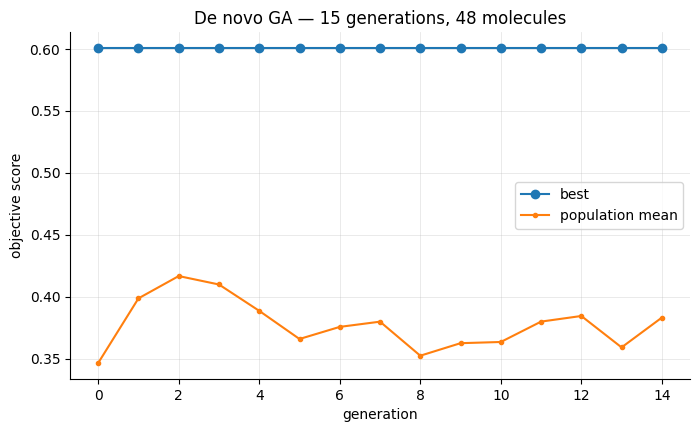

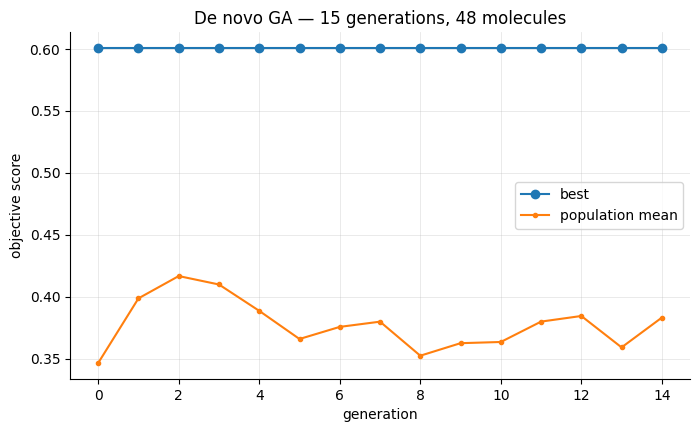

In [10]:
from pharmaml.viz import new_figure

print("top-8 de novo leaderboard (breakdown columns come free):")
print(ga_denovo.to_dataframe().head(8).to_string(index=False))

history = ga_denovo.history
fig_ga, ax_ga = new_figure(figsize=(8.0, 4.5))
ax_ga.plot([h["generation"] for h in history], [h["best_score"] for h in history],
           marker="o", label="best")
ax_ga.plot([h["generation"] for h in history], [h["mean_score"] for h in history],
           marker=".", label="population mean")
ax_ga.set(xlabel="generation", ylabel="objective score",
          title="De novo GA — 15 generations, 48 molecules")
ax_ga.legend()
fig_ga


## 5 · Seeded generation — start from your own molecules

The same optimiser, **seeded mode**: your molecules anchor generation 0 and
the search explores their neighbourhood (corpus molecules pad the rest of
the population, so your chemistry is explored *alongside* the corpus's
diversity — pass `corpus=seed_smiles` too for a strictly seed-isolated run).

One honest observation to expect below: when the objective itself
rewards similarity to a seed, the seed is already a strong local optimum —
the seeded run's best molecule may simply *be* your seed.

CLI equivalent:

```bash
pharmaml generative run --method ga --recipe similar --seeds examples/data/seed_molecules.csv
```


In [11]:
ga_seeded = GeneticOptimizer(
    objective, population_size=48, generations=15, seed=SEED
).optimize(seed_smiles=seed_smiles)

print(ga_seeded.summary())

pd.DataFrame(
    {
        "run": ["de novo", "seeded"],
        "best_score": [ga_denovo.best_score, ga_seeded.best_score],
        "best_smiles": [ga_denovo.best, ga_seeded.best],
        "unique": [len(ga_denovo), len(ga_seeded)],
        "elapsed_s": [ga_denovo.metadata["elapsed_s"], ga_seeded.metadata["elapsed_s"]],
    }
).round({"best_score": 3, "elapsed_s": 1})


genetic_algorithm: 613 unique molecule(s) from 15 iteration(s) in 1.8s -- best 'CC(=O)Oc1ccccc1C(=O)O' (score 0.699)


,run,best_score,best_smiles,unique,elapsed_s
0,de novo,0.601,CCOc1ccc(NC(C)=O)cc1,613,1.5
1,seeded,0.699,CC(=O)Oc1ccccc1C(=O)O,613,1.8


## 6 · Lead optimisation — scaffold-preserving mutation

`mutation="scaffold"` swaps the variation operator: instead of editing
characters (which routinely destroys ring systems), each offspring keeps its
parent's **Murcko framework verbatim** and resamples only the decorations.
The guarantee is structural, not lucky: a Murcko decoration is always
acyclic — any ring would be part of the framework — so re-attaching one
cannot change the scaffold. Acyclic parents (no framework to keep) fall
back to character mutation rather than stalling evolution.

The A/B below pins it down: both runs start from the same 12 seeds with the
corpus constrained to the seeds, then uniform mutation scrambles frameworks
while scaffold mode keeps every molecule on a seed scaffold.


In [12]:
from rdkit import RDLogger
from rdkit.Chem.Scaffolds import MurckoScaffold

RDLogger.DisableLog("rdApp.error")  # keep re-attachment noise out of the output

seed_frameworks = {
    MurckoScaffold.MurckoScaffoldSmilesFromSmiles(s) for s in seed_smiles
}
print(f"{len(seed_smiles)} seeds carry {len(seed_frameworks)} distinct Murcko frameworks")

runs = {}
for mode in ("scaffold", "uniform"):
    runs[mode] = GeneticOptimizer(
        objective, population_size=12, generations=12, seed=SEED, mutation=mode
    ).optimize(seed_smiles=seed_smiles, corpus=seed_smiles)

retention = pd.Series(
    {
        mode: sum(
            1
            for s in result.smiles
            if MurckoScaffold.MurckoScaffoldSmilesFromSmiles(s) in seed_frameworks
        )
        / len(result.smiles)
        for mode, result in runs.items()
    },
    name="fraction on a seed framework",
)
retention.round(3)


12 seeds carry 7 distinct Murcko frameworks


scaffold    1.000
uniform     0.505
Name: fraction on a seed framework, dtype: float64

The trade-off is visible in the scores: uniform mutation reaches higher
objective scores in this short run *because* it may leave the seed
frameworks entirely — scaffold mode spends its exploration budget inside
the chemistry you asked it to keep. The leaderboard's `murcko` column shows
exactly which seed framework each winner sits on.


In [13]:
ga_scaffold = runs["scaffold"]
scaffold_frame = ga_scaffold.to_dataframe().head(6).copy()
scaffold_frame["murcko"] = [
    MurckoScaffold.MurckoScaffoldSmilesFromSmiles(s) for s in scaffold_frame["smiles"]
]
print(f"scaffold mode: best {ga_scaffold.best_score:.3f} "
      f"(uniform mode: {runs['uniform'].best_score:.3f})")
scaffold_frame.round(3)


scaffold mode: best 0.699 (uniform mode: 0.774)


,rank,smiles,score,qed,logp_band,similarity,murcko
0,1,CC(=O)Oc1ccccc1C(=O)O,0.699,0.550,0.788,1.000,c1ccccc1
1,2,CC(C(=O)O)c1ccccc1C(=O)O,0.685,0.765,0.913,0.412,c1ccccc1
2,3,COc1ccccc1C(C)C(=O)O,0.680,0.772,0.993,0.361,c1ccccc1
3,4,CCN(CC)CC(=O)Nc1ccccc1C(=O)O,0.672,0.805,0.945,0.333,c1ccccc1
4,5,CC(C(=O)O)c1ccccc1C(C)C(=O)O,0.670,0.817,0.998,0.303,c1ccccc1
5,6,O=C(O)c1ccccc1Cl,0.667,0.676,0.999,0.433,c1ccccc1


## 6b · Scaffold hopping — cut two parents, recombine the fragments

`crossover="scaffold_hop"` is recombination with chemistry bookkeeping:
both parents are cut at *homologous* bonds — the join atoms match on
element, degree, aromaticity and formal charge — and recombined with
`Chem.molzip`. Three geometries compete for the draw: **bridge cuts**
(a pair of single acyclic bonds, fragments swapped cross-wise — every
ring system arrives intact, and whenever the parents' frameworks span
different fragments the child's Murcko scaffold differs from *both*
parents, Nicolaou et al.'s BREED tradition), plus the two **ring-bond
cuts** below. The operator also works standalone —
`scaffold_hop_crossover(parent_a, parent_b, rng)` — for surgical use
outside the GA.


In [14]:
import random

from pharmaml.generative import GeneticOptimizer, scaffold_hop_crossover

# standalone: aspirin x naproxen, one homologous cut in each parent
draw = random.Random(0)
hybrid = scaffold_hop_crossover(seed_smiles[0], seed_smiles[9], draw)
print(f"parent A:  {seed_smiles[0]}   (aspirin)")
print(f"parent B:  {seed_smiles[9]}   (naproxen)")
print(f"hybrid:    {hybrid}\n")

# in the GA: framework recombination + decoration resampling together
ga_hop = GeneticOptimizer(
    objective, population_size=48, generations=15, seed=SEED,
    mutation="scaffold", crossover="scaffold_hop",
).optimize(seed_smiles=seed_smiles)
print(f"structural mode: {len(ga_hop)} unique, best {ga_hop.best_score:.3f}")
ga_hop.to_dataframe().head(5)[["smiles", "score", "rank"]]


parent A:  CC(=O)Oc1ccccc1C(=O)O   (aspirin)
parent B:  COc1ccc2cc(C(C)C(=O)O)ccc2c1   (naproxen)
hybrid:    COc1ccc2cc(C(C)C(=O)C(=O)c3ccccc3OC(C)=O)ccc2c1



structural mode: 517 unique, best 0.699


,smiles,score,rank
0,CC(=O)Oc1ccccc1C(=O)O,0.698861,1
1,CCc1ccccc1C(=O)O,0.685203,2
2,CCOC(=O)c1ccccc1C(=O)O,0.685092,3
3,CC(C)c1ccccc1C(=O)O,0.677573,4
4,CSc1ccccc1C(=O)O,0.673145,5


### Ring topology — the ring-bond cuts

Bridge cuts recombine fragment *arrangement*; ring topology needs its own
moves, and the operator has two (single ring bonds only — an aromatic
ring bond would make the re-zip invent bond orders, so those are never
cut):

* **merge** — both parents are cut at homologous single ring bonds and the
  two opened rings zip into *one* combined ring holding atoms from both
  (morpholine × piperidine below → a single 12-ring carrying both
  nitrogens and the oxygen);
* **transplant** — a two-ended linker atom (acyclic, two single bonds,
  homologous flanks) is excised from one parent and zipped into a cut
  ring bond of the other: ring homologation — the corpus
  benzodiazepinone's 7-ring below becomes an 8-ring oxazepinone with
  aspirin's ester oxygen.

The parents are looked up from the bundled corpus by SMILES value —
nothing is invented inline.


In [15]:
# ring topology recombination -- both geometries, corpus molecules only
def ring_sizes(smiles):
    """Ring-size profile (small ring first) for the demo prints."""
    mol = rdkit.Chem.MolFromSmiles(smiles)
    return sorted(len(r) for r in mol.GetRingInfo().AtomRings())

draw = random.Random(0)

# merge: two opened rings zip into ONE combined ring (atoms from both)
morpholine = DEFAULT_CORPUS[DEFAULT_CORPUS.index("C1COCCN1")]
piperidine = DEFAULT_CORPUS[DEFAULT_CORPUS.index("C1CCNCC1")]
merged = scaffold_hop_crossover(morpholine, piperidine, draw)
print(f"morpholine : {morpholine}   rings={ring_sizes(morpholine)}")
print(f"piperidine : {piperidine}   rings={ring_sizes(piperidine)}")
print(f"merged     : {merged}   rings={ring_sizes(merged)}  <- one 12-ring\n")

# transplant: a linker atom is excised from one parent and zipped into a
# cut ring bond of the other -- ring homologation
benzodiazepinone = DEFAULT_CORPUS[DEFAULT_CORPUS.index("CC1=NCC(=O)N(C)c2ccccc21")]
aspirin = DEFAULT_CORPUS[DEFAULT_CORPUS.index("CC(=O)Oc1ccccc1C(=O)O")]
transplanted = scaffold_hop_crossover(benzodiazepinone, aspirin, draw)
print(f"ring parent  : {benzodiazepinone}   rings={ring_sizes(benzodiazepinone)}")
print(f"linker donor : {aspirin}   (the ester O is a two-ended linker)")
print(
    f"transplanted : {transplanted}   rings={ring_sizes(transplanted)}"
    "  <- the 7-ring expanded to an 8-ring"
)


morpholine : C1COCCN1   rings=[6]
piperidine : C1CCNCC1   rings=[6]
merged     : C1CCNCCOCCNCC1   rings=[12]  <- one 12-ring

ring parent  : CC1=NCC(=O)N(C)c2ccccc21   rings=[6, 7]
linker donor : CC(=O)Oc1ccccc1C(=O)O   (the ester O is a two-ended linker)
transplanted : CC1=NCC(=O)N(C)c2ccccc2O1   rings=[6, 8]  <- the 7-ring expanded to an 8-ring


## 7 · Reinforcement learning — a prior that writes SMILES, then a policy that bends it

`ReinventOptimizer` is the REINVENT-style pipeline, in two acts:

1. **Prior** — `SmilesRnn`, a character-level GRU trained on the corpus:
   it learns the *grammar* of drug-like SMILES (which characters follow
   which), nothing about the objective yet;
2. **Fine-tuning** — the same network becomes the *policy*: REINFORCE with
   a running baseline (the score advantage), an entropy bonus (don't
   collapse onto one spelling), a prior anchor (don't drift into
   un-chemical strings), and experience replay. The objective is the
   reward.

Honest scope: this is a compact, CPU-sized implementation of the REINVENT
*recipe* — not a replication of the full AstraZeneca stack.


char-GRU prior: 8 epochs, loss 2.62 -> 1.11


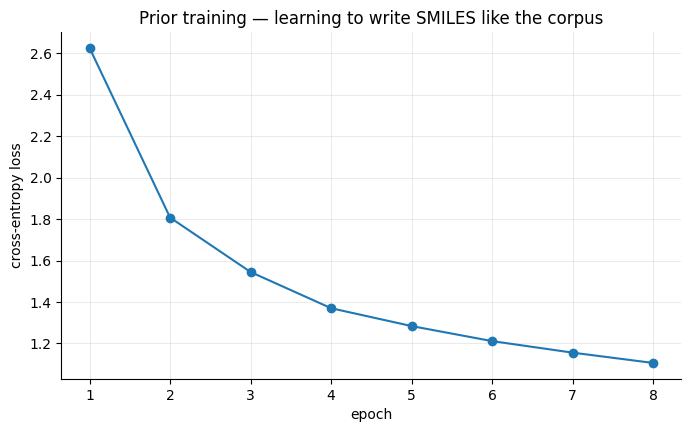

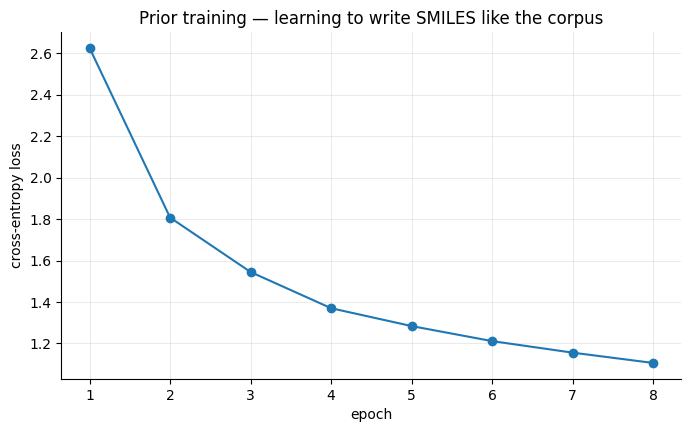

In [16]:
from pharmaml.generative import SmilesRnn

prior = SmilesRnn(hidden_dim=96, seed=SEED)
losses = prior.train_prior(DEFAULT_CORPUS, epochs=8)
print(f"char-GRU prior: {len(losses)} epochs, loss {losses[0]:.2f} -> {losses[-1]:.2f}")

fig_prior, ax_prior = new_figure(figsize=(8.0, 4.5))
ax_prior.plot(range(1, len(losses) + 1), losses, marker="o")
ax_prior.set(xlabel="epoch", ylabel="cross-entropy loss",
             title="Prior training — learning to write SMILES like the corpus")
fig_prior


With the prior trained, fine-tune it toward the §3 objective. A score
plateau triggers the built-in early stop — RL runs until it stops
improving, not until the iteration budget burns out (this run kept
improving to the final iteration, so the stop never fired).


In [17]:
from pharmaml.generative import ReinventOptimizer

rl = ReinventOptimizer(
    objective, prior=prior, iterations=15, batch_size=32, seed=SEED
).optimize()

print(rl.summary())
print(f"early stopped   : {rl.metadata['early_stopped']} (mean-score plateau)")
print(f"unique output   : {len(rl)} molecules in {rl.metadata['elapsed_s']:.1f} s")


reinforce_rl: 107 unique molecule(s) from 15 iteration(s) in 0.7s -- best 'CC(=O)CCc1ccccc1' (score 0.601)
early stopped   : False (mean-score plateau)
unique output   : 107 molecules in 0.7 s


The RL history carries the mean batch score and the best-so-far curve per
iteration — the classic REINVENT diagnostic pair.


top-6 RL leaderboard:
 rank                smiles    score      qed  logp_band  similarity
    1      CC(=O)CCc1ccccc1 0.600976 0.641895   0.978560    0.323529
    2 CC(=O)C(=O)CCc1ccccc1 0.598053 0.655116   0.975507    0.305556
    3          CCOc1ccccc1O 0.597255 0.674684   0.978376    0.285714
    4       CC(=O)Cc1ccccc1 0.591929 0.602575   0.983592    0.343750
    5  CC(=O)C(=O)Cc1ccccc1 0.570790 0.629170   0.828812    0.323529
    6        CC(=O)c1ccccc1 0.563439 0.517047   0.993880    0.379310


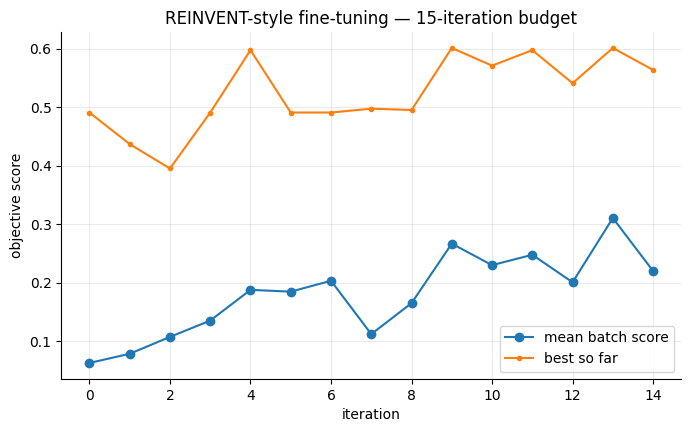

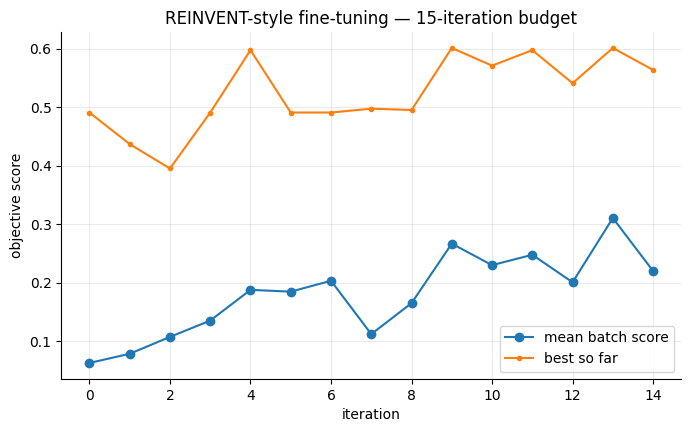

In [18]:
rl_history = pd.DataFrame(rl.history)

fig_rl, ax_rl = new_figure(figsize=(8.0, 4.5))
ax_rl.plot(rl_history["iteration"], rl_history["mean_score"],
           marker="o", label="mean batch score")
ax_rl.plot(rl_history["iteration"], rl_history["best_score"],
           marker=".", label="best so far")
ax_rl.set(xlabel="iteration", ylabel="objective score",
          title="REINVENT-style fine-tuning — 15-iteration budget")
ax_rl.legend()

print("top-6 RL leaderboard:")
print(rl.to_dataframe().head(6).to_string(index=False))
fig_rl


## 8 · Novelty — the anti-rediscovery recipe

Rediscovering the corpus is the failure mode of pure similarity search:
the "best" molecule is just a corpus member re-spelled. `NoveltyObjective`
(`1 − max` Tanimoto vs the corpus) makes rediscovery score exactly 0 —
pair it with QED so the search stays drug-like *while* leaving the corpus.

The honest trade-off, visible right in the output: unconstrained novelty
rewards strange chemistry (exotic sulfide rings below) — the weight vector
is your dial between "safe and similar" and "new and weird".


In [19]:
novelty_objective = MultiObjective(
    [QedObjective(), NoveltyObjective()], weights=[0.5, 0.5]
)
ga_novel = GeneticOptimizer(
    novelty_objective, population_size=48, generations=15, seed=SEED
).optimize()

print(ga_novel.summary())
ga_novel.to_dataframe().head(6).round(3)


genetic_algorithm: 635 unique molecule(s) from 15 iteration(s) in 1.5s -- best 'OCC1CCCPCCC1SC1CCPSC1' (score 0.838)


,rank,smiles,score,qed,novelty
0,1,OCC1CCCPCCC1SC1CCPSC1,0.838,0.803,0.875
1,2,OCC1CCCPCCCC1SC1CCSC1,0.838,0.805,0.872
2,3,OCCC1CC=NPCCSCPCSC1,0.835,0.795,0.878
3,4,OCC1CCCPC=C1SC1CCPS1,0.835,0.796,0.875
4,5,CC1NPCC=CN=C=C1PSCF,0.834,0.779,0.894
5,6,OC=C(NC1=CN=CC=CSC1)C1=CC=CC=CCC=C1,0.834,0.769,0.903


## 9 · GA vs RL — same objective, same seed, head-to-head

The two optimisers are complementary, not competing: the GA explores a
wide combinatorial space cheaply; RL trains a *policy* that can then
generate on its own. On this objective and budget the numbers land where
they land — the interesting line is the last one: whether the two searches
even visit the same molecules.

CLI twins for both:

```bash
pharmaml generative run --method ga --recipe druglike --iterations 20 --seed 42
pharmaml generative run --method rl --recipe druglike --iterations 15 --out molecules.csv
```


In [20]:
methods = pd.DataFrame(
    {
        "method": ["ga (de novo)", "ga (seeded)", "rl"],
        "best_score": [ga_denovo.best_score, ga_seeded.best_score, rl.best_score],
        "best_smiles": [ga_denovo.best, ga_seeded.best, rl.best],
        "unique": [len(ga_denovo), len(ga_seeded), len(rl)],
        "elapsed_s": [
            ga_denovo.metadata["elapsed_s"],
            ga_seeded.metadata["elapsed_s"],
            rl.metadata["elapsed_s"],
        ],
    }
)
print(methods.to_string(index=False))

overlap = set(ga_denovo.smiles[:10]) & set(rl.smiles[:10])
print(f"\ntop-10 overlap GA (de novo) vs RL: "
      f"{overlap or 'none — two searches, different corners'}")


      method  best_score           best_smiles  unique  elapsed_s
ga (de novo)    0.600755  CCOc1ccc(NC(C)=O)cc1     613   1.516201
 ga (seeded)    0.698861 CC(=O)Oc1ccccc1C(=O)O     613   1.849223
          rl    0.600976      CC(=O)CCc1ccccc1     107   0.699900

top-10 overlap GA (de novo) vs RL: {'CC(=O)c1ccccc1'}


## 10 · Publish — the leaderboard and the one-click bundle

Every run's leaderboard concatenates into one ranked table (method column
attached), the CSV lands in `WORK`, and `save_visual_bundle` publishes the
four inline figures + tables + headline metrics as a shareable
report directory — the same call the other four workflow notebooks end on.


In [21]:
from pharmaml.viz import save_visual_bundle

leaderboard = pd.concat(
    [
        ga_denovo.to_dataframe().assign(method="ga_de_novo"),
        ga_seeded.to_dataframe().assign(method="ga_seeded"),
        ga_novel.to_dataframe().assign(method="ga_novel"),
        rl.to_dataframe().assign(method="rl"),
    ],
    ignore_index=True,
)
leaderboard.to_csv(WORK / "generative_leaderboard.csv", index=False)
print(f"leaderboard: {len(leaderboard)} rows -> {WORK / 'generative_leaderboard.csv'}")

artifacts = save_visual_bundle(
    figures={
        "corpus_landscape": fig_landscape,
        "ga_convergence": fig_ga,
        "prior_training": fig_prior,
        "rl_finetuning": fig_rl,
    },
    tables={"leaderboard": leaderboard.head(50), "methods": methods},
    metrics={
        "best_score_ga": ga_denovo.best_score,
        "best_score_rl": rl.best_score,
        "corpus_size": len(DEFAULT_CORPUS),
    },
    out_dir=WORK / "report",
    title="Molecule generation workflow — GA + RL on a curated corpus",
    subtitle=(f"QED + LogP + similarity objective · {len(leaderboard)} "
              f"ranked molecules · seed {SEED}"),
    formats=("png", "svg"),
    close=True,   # figures already rendered inline above; free the memory
)
for path in artifacts:
    print(f"  {path.relative_to(WORK)}")


leaderboard: 1968 rows -> /tmp/generative_workflow_v67mknp4/generative_leaderboard.csv


  report/report.html
  report/leaderboard.csv
  report/leaderboard.md
  report/methods.csv
  report/methods.md
  report/corpus_landscape.png
  report/corpus_landscape.svg
  report/ga_convergence.png
  report/ga_convergence.svg
  report/prior_training.png
  report/prior_training.svg
  report/rl_finetuning.png
  report/rl_finetuning.svg


## 11 · Recap

One notebook, the full molecule-building story:

* **Corpus** — 244 curated drug-like SMILES, validated in place (§1);
* **Objectives** — seven ready-made scores: four property bands + QED,
  similarity, pharmacophore, novelty (§2);
* **Multi-objective** — weighted geometric mean where one zero vetoes the
  molecule (§3);
* **De novo GA** — 613 unique molecules in seconds, per-generation history
  and free breakdown columns (§4);
* **Seeded GA** — your own molecules anchor the search (§5);
* **Lead optimisation** — scaffold-preserving mutation kept 100 % of the
  run on seed frameworks vs 50.5 % for uniform mutation (§6);
* **RL** — a char-GRU prior learned the corpus grammar, then REINVENT-style
  fine-tuning bent it toward the objective; the plateau early-stop stayed
  armed but never fired — the mean score improved to the last iteration
  (§7);
* **Novelty** — the anti-rediscovery recipe, honestly showing its
  strange-chemistry trade-off (§8);
* **GA vs RL** — same objective, complementary searches (§9);
* **Publish** — leaderboard CSV + one-click visual bundle (§10).

Where to go next:

* the runnable script twin: `examples/run_generative_design.py` (~10 s);
* the CLI: `pharmaml generative run --method ga|rl --recipe
  qed|logp|druglike|similar|novel` (+ `--scaffold`, `--seeds`);
* the README's generative section for the scope notes (what the RL is and
  is not, what scaffold mode guarantees).
